https://www.tensorflow.org/tutorials/structured_data/time_series

In [1]:
import os
import datetime

import IPython
import IPython.display
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

mpl.rcParams['figure.figsize'] = (8, 6)
mpl.rcParams['axes.grid'] = False


I0000 00:00:1794836748.679222 3330090 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794836748.711439 3330090 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794836749.425064 3330090 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32")
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32")
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32")
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32")
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [ data_1, data_2, data_3] #data_0, #get better results without data_0

df = pd.concat(data_list, ignore_index=True)
# df.rename( columns={'Unnamed: 0':'order'}, inplace=True )
df = df[["s0", "s1", "s2", "cx_mm", "cy_mm"]]
df.head()

# date_time = df["order"] #to help follow the tutorial code
# date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')


,s0,s1,s2,cx_mm,cy_mm
0,0.0,0.0,0.0,0.009091,0.000000
1,0.0,0.0,0.0,-0.009091,0.000000
2,6144.0,-8393.0,2249.0,1.972727,1.745455
3,6144.0,-7949.0,1805.0,1.827273,1.727273
4,6144.0,-7506.0,1362.0,1.681818,1.690909


In [3]:
df[600:700:1]


,s0,s1,s2,cx_mm,cy_mm
600,-6144.0,8171.0,-2027.0,-1.409091,-1.436364
601,-6144.0,7949.0,-1805.0,-1.318182,-1.436364
602,-6144.0,7728.0,-1584.0,-1.209091,-1.418182
603,-6144.0,7284.0,-1140.0,-1.081818,-1.418182
604,-6144.0,7062.0,-918.0,-1.009091,-1.418182
...,...,...,...,...,...
695,-4608.0,6960.0,-2352.0,-1.245455,-0.909091
696,-4608.0,6738.0,-2130.0,-1.154545,-0.909091
697,-4608.0,6516.0,-1908.0,-1.081818,-0.909091
698,-4608.0,6294.0,-1686.0,-1.027273,-0.909091


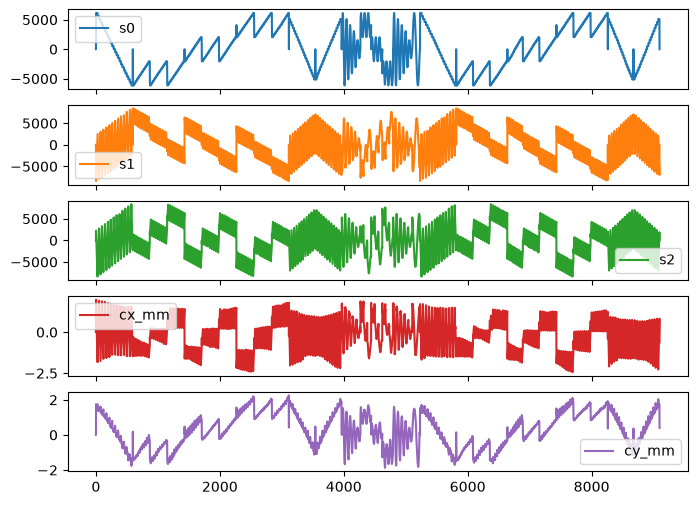

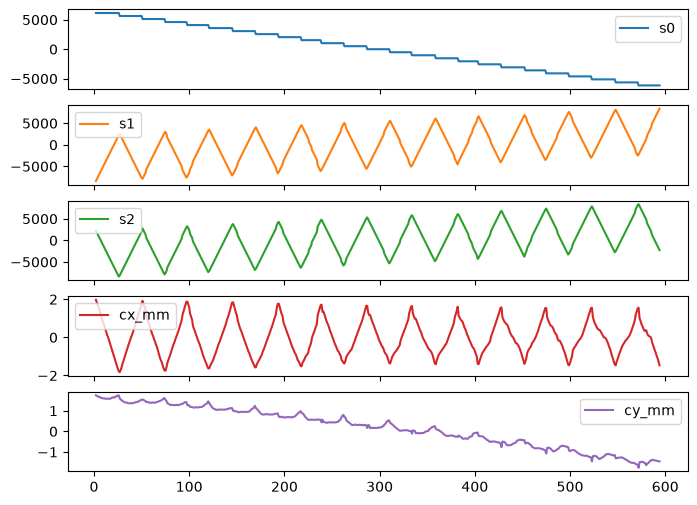

In [4]:
plot_cols = ['s0', 's1', 's2', 'cx_mm', 'cy_mm']
plot_features = df[plot_cols]
plot_features.index = plot_features.index
_ = plot_features.plot(subplots=True)

plot_features = df[plot_cols][2:595:1]
plot_features.index = plot_features.index
_ = plot_features.plot(subplots=True)


/tmp/ipykernel_3330090/2095093864.py:14: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim([0.00, max(plt.xlim())])


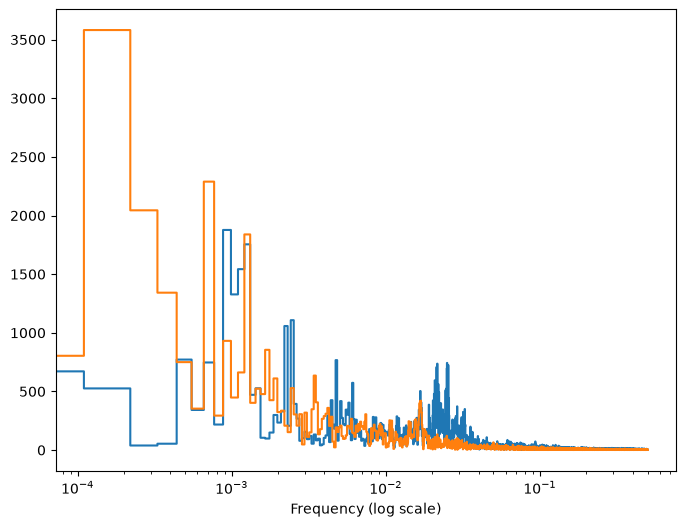

In [10]:
fft = tf.signal.rfft(df['cx_mm']) #[2:595:1])
fft_y = tf.signal.rfft(df['cy_mm']) #[2:595:1])
f_per_dataset = np.arange(0, len(fft))

n_samples_h = len(df['cx_mm']) #[2:595:1])
# hours_per_year = 24*365.2524
# years_per_dataset = n_samples_h/(hours_per_year)

f_per_year = f_per_dataset/n_samples_h
plt.step(f_per_year, np.abs(fft))
plt.step(f_per_year, np.abs(fft_y))
plt.xscale('log')
# plt.ylim(0, 400000)
plt.xlim([0.00, max(plt.xlim())])
# plt.xticks([1, 365.2524], labels=['1/Year', '1/day'])
_ = plt.xlabel('Frequency (log scale)')

(70%, 20%, 10%) split for the training, validation, and test sets. Note the data is not being randomly shuffled before splitting. This is for two reasons:

    It ensures that chopping the data into windows of consecutive samples is still possible.
    It ensures that the validation/test results are more realistic, being evaluated on the data collected after the model was trained.


In [67]:
column_indices = {name: i for i, name in enumerate(df.columns)}

n = len(df)
train_df = df[0:int(n*0.7)]
val_df = df[int(n*0.7):int(n*0.9)]
test_df = df[int(n*0.9):]

num_features = df.shape[1]


Normalize the data

The mean and standard deviation should only be computed using the training data so that the models have no access to the values in the validation and test sets.

In [68]:
train_mean = train_df.mean()
train_std = train_df.std()

train_df = (train_df - train_mean) / train_std
val_df = (val_df - train_mean) / train_std
test_df = (test_df - train_mean) / train_std


/tmp/ipykernel_1219256/2828228499.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  _ = ax.set_xticklabels(df.keys(), rotation=90)


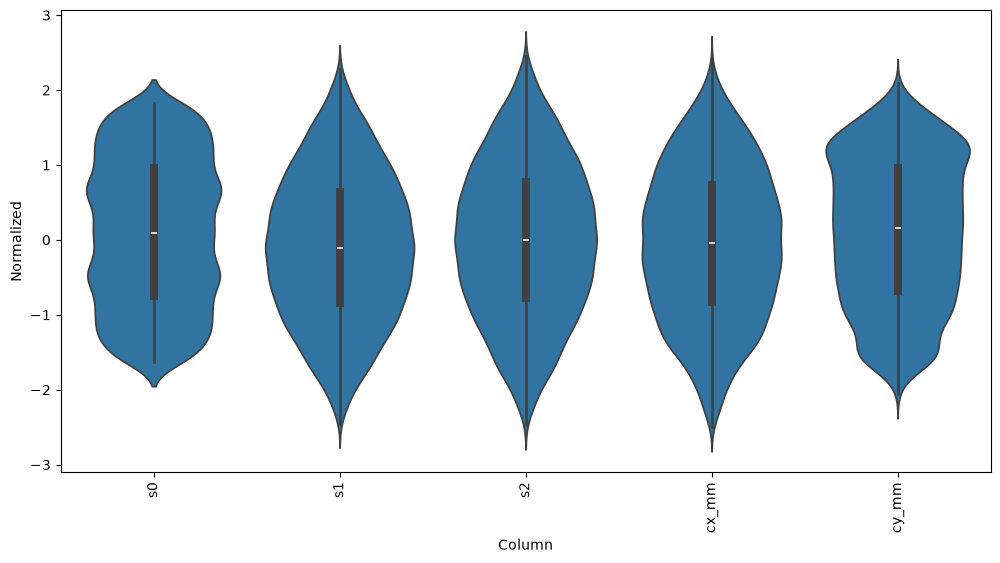

In [69]:
df_std = (df - train_mean) / train_std
df_std = df_std.melt(var_name='Column', value_name='Normalized')
plt.figure(figsize=(12, 6))
ax = sns.violinplot(x='Column', y='Normalized', data=df_std)
_ = ax.set_xticklabels(df.keys(), rotation=90)


<h2> Data Windowing

In [70]:
class WindowGenerator():
  def __init__(self, input_width, label_width, shift,
               train_df=train_df, val_df=val_df, test_df=test_df,
               label_columns=None):
    # Store the raw data.
    self.train_df = train_df
    self.val_df = val_df
    self.test_df = test_df

    # Work out the label column indices.
    self.label_columns = label_columns
    if label_columns is not None:
      self.label_columns_indices = {name: i for i, name in
                                    enumerate(label_columns)}
    self.column_indices = {name: i for i, name in
                           enumerate(train_df.columns)}

    # Work out the window parameters.
    self.input_width = input_width
    self.label_width = label_width
    self.shift = shift

    self.total_window_size = input_width + shift

    self.input_slice = slice(0, input_width)
    self.input_indices = np.arange(self.total_window_size)[self.input_slice]

    self.label_start = self.total_window_size - self.label_width
    self.labels_slice = slice(self.label_start, None)
    self.label_indices = np.arange(self.total_window_size)[self.labels_slice]

  def __repr__(self):
    return '\n'.join([
        f'Total window size: {self.total_window_size}',
        f'Input indices: {self.input_indices}',
        f'Label indices: {self.label_indices}',
        f'Label column name(s): {self.label_columns}'])


In [73]:
w2 = WindowGenerator(input_width=6, label_width=1, shift=1,
                     label_columns=['s0'])
w2



Total window size: 7
Input indices: [0 1 2 3 4 5]
Label indices: [6]
Label column name(s): ['s0']

<h3> Window splitting

In [75]:
# Stack three slices, the length of the total window.
example_window = tf.stack([np.array(train_df[:w2.total_window_size]),
                           np.array(train_df[100:100+w2.total_window_size]),
                           np.array(train_df[200:200+w2.total_window_size])])

example_inputs, example_labels = w2.split_window(example_window)

print('All shapes are: (batch, time, features)')
print(f'Window shape: {example_window.shape}')
print(f'Inputs shape: {example_inputs.shape}')
print(f'Labels shape: {example_labels.shape}')


All shapes are: (batch, time, features)
Window shape: (3, 7, 5)
Inputs shape: (3, 6, 5)
Labels shape: (3, 1, 1)


In [76]:
w2.example = example_inputs, example_labels


In [ ]:
def plot(self, model=None, plot_col='s0', max_subplots=3):
  inputs, labels = self.example
  plt.figure(figsize=(12, 8))
  plot_col_index = self.column_indices[plot_col]
  max_n = min(max_subplots, len(inputs))
  for n in range(max_n):
    plt.subplot(max_n, 1, n+1)
    plt.ylabel(f'{plot_col} [normed]')
    plt.plot(self.input_indices, inputs[n, :, plot_col_index],
             label='Inputs', marker='.', zorder=-10)

    if self.label_columns:
      label_col_index = self.label_columns_indices.get(plot_col, None)
    else:
      label_col_index = plot_col_index

    if label_col_index is None:
      continue

    plt.scatter(self.label_indices, labels[n, :, label_col_index],
                edgecolors='k', label='Labels', c='#2ca02c', s=64)
    if model is not None:
      predictions = model(inputs)
      plt.scatter(self.label_indices, predictions[n, :, label_col_index],
                  marker='X', edgecolors='k', label='Predictions',
                  c='#ff7f0e', s=64)

    if n == 0:
      plt.legend()

  plt.xlabel('Time')

WindowGenerator.plot = plot


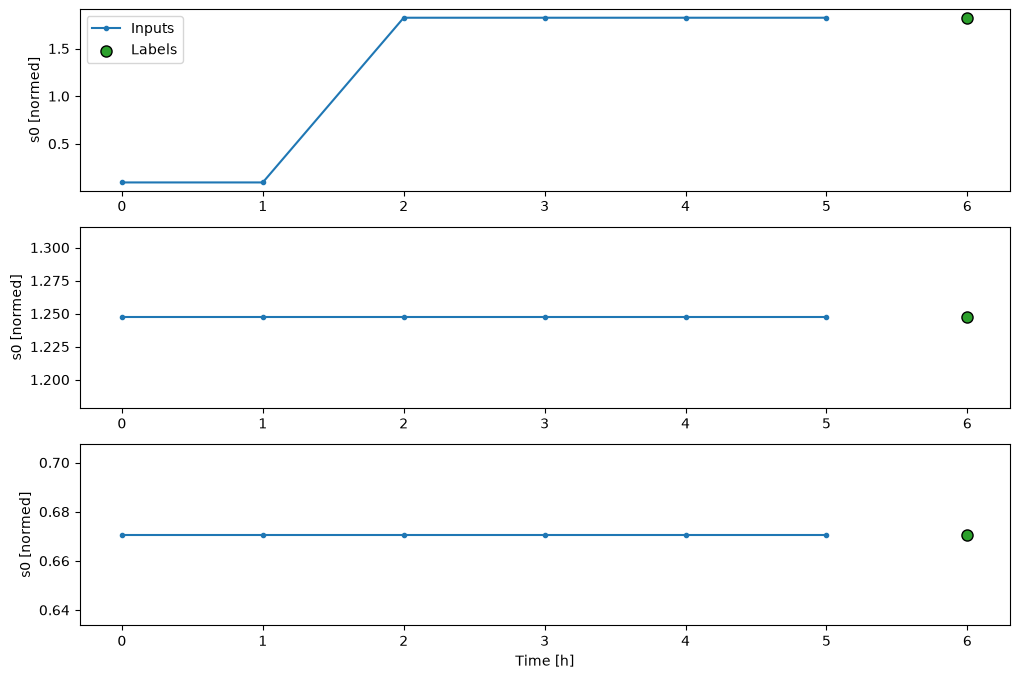

In [80]:
w2.plot()


<h3> Create tf.data.Datasets</h3>
Finally, this make_dataset method will take a time series DataFrame and convert it to a tf.data.Dataset of (input_window, label_window) pairs using the tf.keras.utils.timeseries_dataset_from_array function:

In [81]:
def make_dataset(self, data):
  data = np.array(data, dtype=np.float32)
  ds = tf.keras.utils.timeseries_dataset_from_array(
      data=data,
      targets=None,
      sequence_length=self.total_window_size,
      sequence_stride=1,
      shuffle=True,
      batch_size=32,)

  ds = ds.map(self.split_window)

  return ds

WindowGenerator.make_dataset = make_dataset


The WindowGenerator object holds training, validation, and test data.

Add properties for accessing them as tf.data.Datasets using the make_dataset method you defined earlier. Also, add a standard example batch for easy access and plotting:

In [82]:
@property
def train(self):
  return self.make_dataset(self.train_df)

@property
def val(self):
  return self.make_dataset(self.val_df)

@property
def test(self):
  return self.make_dataset(self.test_df)

@property
def example(self):
  """Get and cache an example batch of `inputs, labels` for plotting."""
  result = getattr(self, '_example', None)
  if result is None:
    # No example batch was found, so get one from the `.train` dataset
    result = next(iter(self.train))
    # And cache it for next time
    self._example = result
  return result

WindowGenerator.train = train
WindowGenerator.val = val
WindowGenerator.test = test
WindowGenerator.example = example


In [83]:
# Each element is an (inputs, label) pair.
w2.train.element_spec


(TensorSpec(shape=(None, 6, 5), dtype=tf.float32, name=None),
 TensorSpec(shape=(None, 1, 1), dtype=tf.float32, name=None))

In [84]:
for example_inputs, example_labels in w2.train.take(1):
  print(f'Inputs shape (batch, time, features): {example_inputs.shape}')
  print(f'Labels shape (batch, time, features): {example_labels.shape}')


Inputs shape (batch, time, features): (32, 6, 5)
Labels shape (batch, time, features): (32, 1, 1)


<h1>Single step models</h1>
predict single feature's value for the next time step, only based on the current time step

In [85]:
single_step_window = WindowGenerator(
    input_width=1, label_width=1, shift=1,
    label_columns=['s0'])
single_step_window


Total window size: 2
Input indices: [0]
Label indices: [1]
Label column name(s): ['s0']

In [86]:
for example_inputs, example_labels in single_step_window.train.take(1):
  print(f'Inputs shape (batch, time, features): {example_inputs.shape}')
  print(f'Labels shape (batch, time, features): {example_labels.shape}')


Inputs shape (batch, time, features): (32, 1, 5)
Labels shape (batch, time, features): (32, 1, 1)


<h3>Baseline</h3>
Predict no change - predict that the next s0 value is equal to the current s0 value.

As we mostly do snake scans, this will work a lot of the time

In [87]:
class Baseline(tf.keras.Model):
  def __init__(self, label_index=None):
    super().__init__()
    self.label_index = label_index

  def call(self, inputs):
    if self.label_index is None:
      return inputs
    result = inputs[:, :, self.label_index]
    return result[:, :, tf.newaxis]


In [88]:
baseline = Baseline(label_index=column_indices['s0'])

baseline.compile(loss=tf.keras.losses.MeanSquaredError(),
                 metrics=[tf.keras.metrics.MeanAbsoluteError()])

val_performance = {}
performance = {}
val_performance['Baseline'] = baseline.evaluate(single_step_window.val, return_dict=True)
performance['Baseline'] = baseline.evaluate(single_step_window.test, verbose=0, return_dict=True)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step - loss: 0.0025 - mean_absolute_error: 0.0081   


That printed some performance metrics, but those don't give you a feeling for how well the model is doing.

The WindowGenerator has a plot method, but the plots won't be very interesting with only a single sample.

So, create a wider WindowGenerator that generates windows 24 hours of consecutive inputs and labels at a time. The new wide_window variable doesn't change the way the model operates. The model still makes predictions one hour into the future based on a single input time step. Here, the time axis acts like the batch axis: each prediction is made independently with no interaction between time steps:

In [89]:
wide_window = WindowGenerator(
    input_width=24, label_width=24, shift=1,
    label_columns=['s0'])

wide_window


Total window size: 25
Input indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Label indices: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
Label column name(s): ['s0']

Input shape: (32, 24, 5)
Output shape: (32, 24, 1)


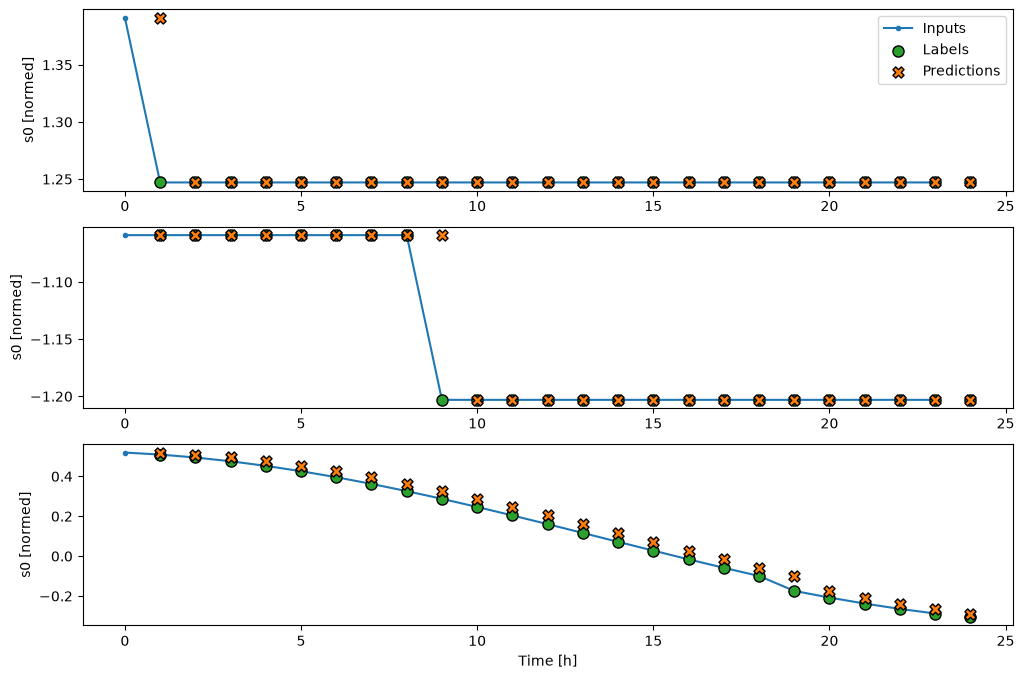

In [90]:
print('Input shape:', wide_window.example[0].shape)
print('Output shape:', baseline(wide_window.example[0]).shape)
wide_window.plot(baseline)


<h1> Linear Model</h3>
A tf.keras.layers.Dense layer with no activation set is a linear model. The layer only transforms the last axis of the data from (batch, time, inputs) to (batch, time, units); it is applied independently to every item across the batch and time axes.

In [91]:
linear = tf.keras.Sequential([
    tf.keras.layers.Dense(units=1)
])
print('Input shape:', single_step_window.example[0].shape)
print('Output shape:', linear(single_step_window.example[0]).shape)


Input shape: (32, 1, 5)
Output shape: (32, 1, 1)


In [92]:
MAX_EPOCHS = 20

def compile_and_fit(model, window, patience=2):
  early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                                    patience=patience,
                                                    mode='min')

  model.compile(loss=tf.keras.losses.MeanSquaredError(),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=[tf.keras.metrics.MeanAbsoluteError()])

  history = model.fit(window.train, epochs=MAX_EPOCHS,
                      validation_data=window.val,
                      callbacks=[early_stopping])
  return history


In [93]:
history = compile_and_fit(linear, single_step_window)

val_performance['Linear'] = linear.evaluate(single_step_window.val, return_dict=True)
performance['Linear'] = linear.evaluate(single_step_window.test, verbose=0, return_dict=True)


Epoch 1/20


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2997 - mean_absolute_error: 0.4414 - val_loss: 0.0940 - val_mean_absolute_error: 0.2534
Epoch 2/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 987us/step - loss: 0.0440 - mean_absolute_error: 0.1576 - val_loss: 0.0130 - val_mean_absolute_error: 0.0827
Epoch 3/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - loss: 0.0162 - mean_absolute_error: 0.0860 - val_loss: 0.0108 - val_mean_absolute_error: 0.0817
Epoch 4/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 792us/step - loss: 0.0148 - mean_absolute_error: 0.0800 - val_loss: 0.0107 - val_mean_absolute_error: 0.0813
Epoch 5/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step - loss: 0.0146 - mean_absolute_error: 0.0789 - val_loss: 0.0104 - val_mean_absolute_error: 0.0797
Epoch 6/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 934us/step - loss: 0.0143 - mean_absolute_error: 0.0777 - val_loss: 0.0101 - val_mean_absolute_error: 0.0780
Epoch 7/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 927us/step - loss: 0.0141 - mean_absolute_error: 0.0765 - 

Input shape: (32, 24, 5)
Output shape: (32, 24, 1)


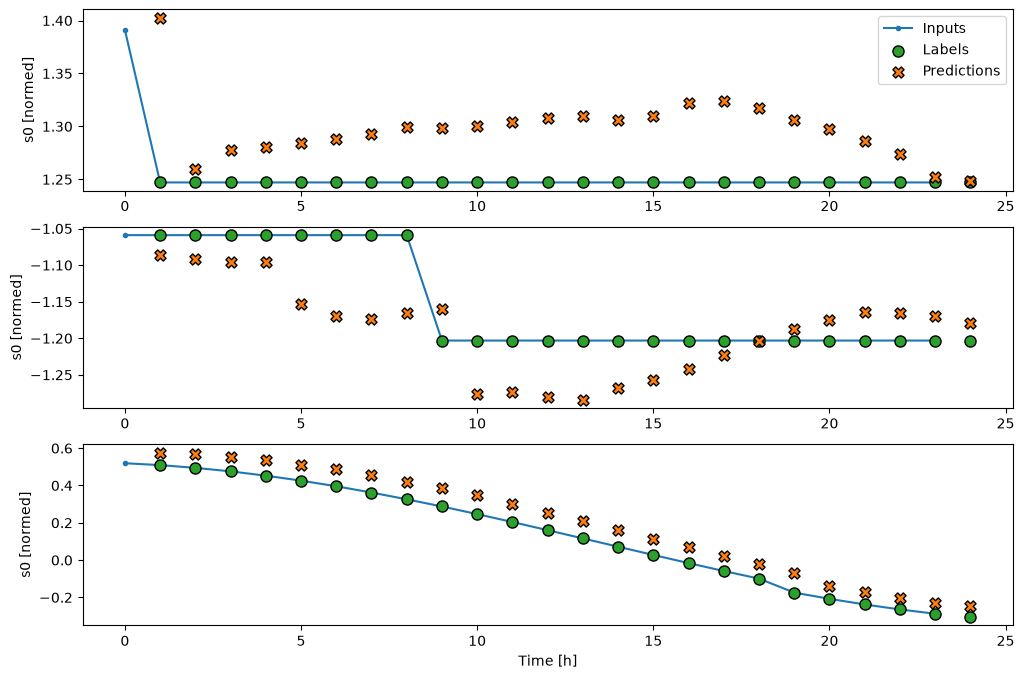

In [94]:
print('Input shape:', wide_window.example[0].shape)
print('Output shape:', linear(wide_window.example[0]).shape)
wide_window.plot(linear)


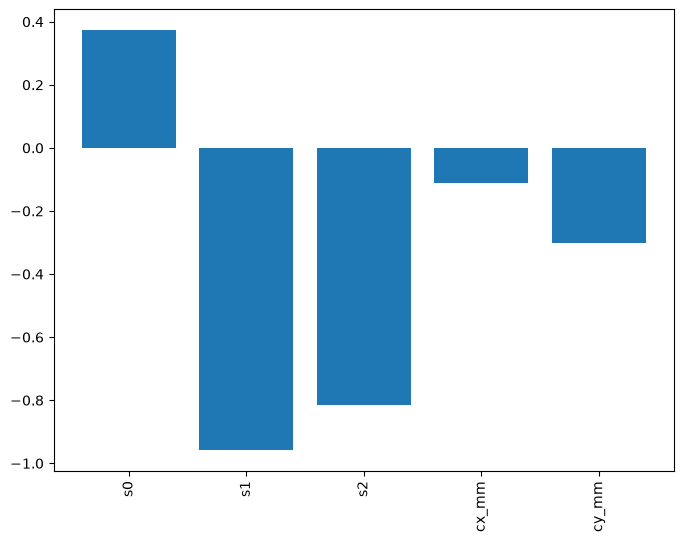

In [95]:
plt.bar(x = range(len(train_df.columns)),
        height=linear.layers[0].kernel[:,0].numpy())
axis = plt.gca()
axis.set_xticks(range(len(train_df.columns)))
_ = axis.set_xticklabels(train_df.columns, rotation=90)


<h1> Dense models

In [96]:
dense = tf.keras.Sequential([
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=1)
])

history = compile_and_fit(dense, single_step_window)

val_performance['Dense'] = dense.evaluate(single_step_window.val, return_dict=True)
performance['Dense'] = dense.evaluate(single_step_window.test, verbose=0, return_dict=True)


Epoch 1/20


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0662 - mean_absolute_error: 0.1171 - val_loss: 0.0037 - val_mean_absolute_error: 0.0353
Epoch 2/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0080 - mean_absolute_error: 0.0383 - val_loss: 0.0030 - val_mean_absolute_error: 0.0265
Epoch 3/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 974us/step - loss: 0.0078 - mean_absolute_error: 0.0348 - val_loss: 0.0034 - val_mean_absolute_error: 0.0324
Epoch 4/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 958us/step - loss: 0.0077 - mean_absolute_error: 0.0350 - val_loss: 0.0028 - val_mean_absolute_error: 0.0230
Epoch 5/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 984us/step - loss: 0.0075 - mean_absolute_error: 0.0338 - val_loss: 0.0031 - val_mean_absolute_error: 0.0291
Epoch 6/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0075 - mean_absolute_error: 0.0339 - val_loss: 0.0028 - val_mean_absolute_error: 0.0235
Epoch 7/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0075 - mean_absolute_error: 0.0349 - val_lo

<h2> Multi-step Dense

In [97]:
CONV_WIDTH = 3
conv_window = WindowGenerator(
    input_width=CONV_WIDTH,
    label_width=1,
    shift=1,
    label_columns=['s0'])

conv_window


Total window size: 4
Input indices: [0 1 2]
Label indices: [3]
Label column name(s): ['s0']

Text(0.5, 0.98, 'Given 3 seconds of inputs, predict 1 second into the future.')

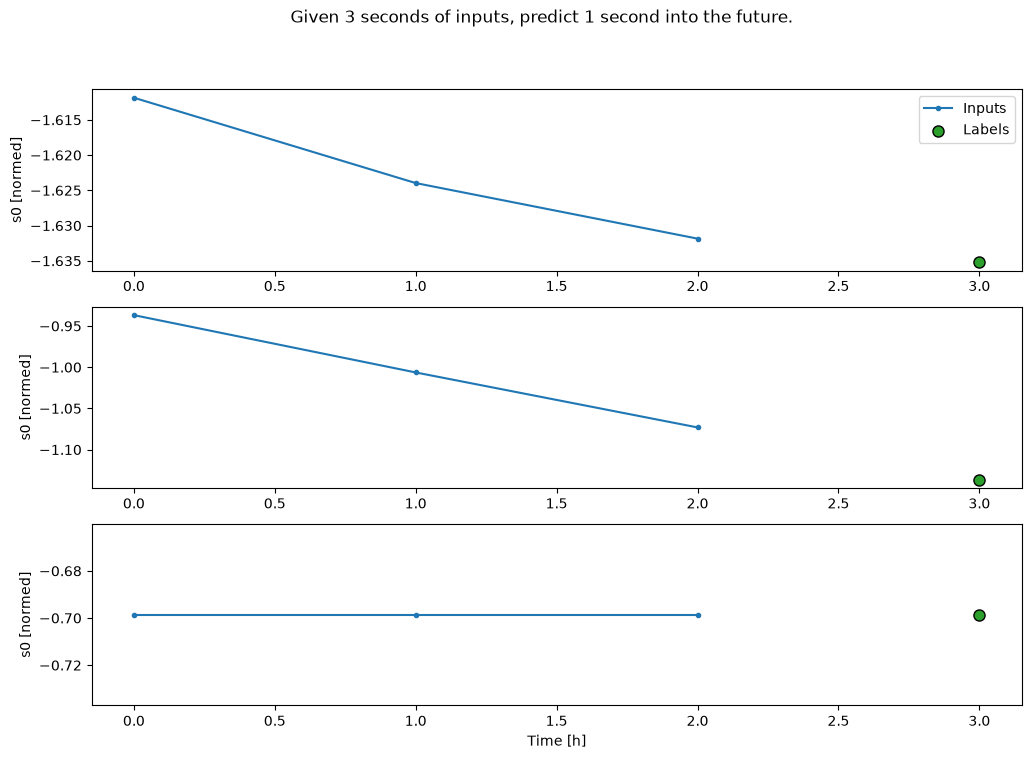

In [98]:
conv_window.plot()
plt.suptitle("Given 3 seconds of inputs, predict 1 second into the future.")


You could train a dense model on a multiple-input-step window by adding a tf.keras.layers.Flatten as the first layer of the model:

In [99]:
multi_step_dense = tf.keras.Sequential([
    # Shape: (time, features) => (time*features)
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=32, activation='relu'),
    tf.keras.layers.Dense(units=32, activation='relu'),
    tf.keras.layers.Dense(units=1),
    # Add back the time dimension.
    # Shape: (outputs) => (1, outputs)
    tf.keras.layers.Reshape([1, -1]),
])
print('Input shape:', conv_window.example[0].shape)
print('Output shape:', multi_step_dense(conv_window.example[0]).shape)


Input shape: (32, 3, 5)
Output shape: (32, 1, 1)


In [100]:
history = compile_and_fit(multi_step_dense, conv_window)

IPython.display.clear_output()
val_performance['Multi step dense'] = multi_step_dense.evaluate(conv_window.val, return_dict=True)
performance['Multi step dense'] = multi_step_dense.evaluate(conv_window.test, verbose=0, return_dict=True)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 725us/step - loss: 0.0024 - mean_absolute_error: 0.0253   


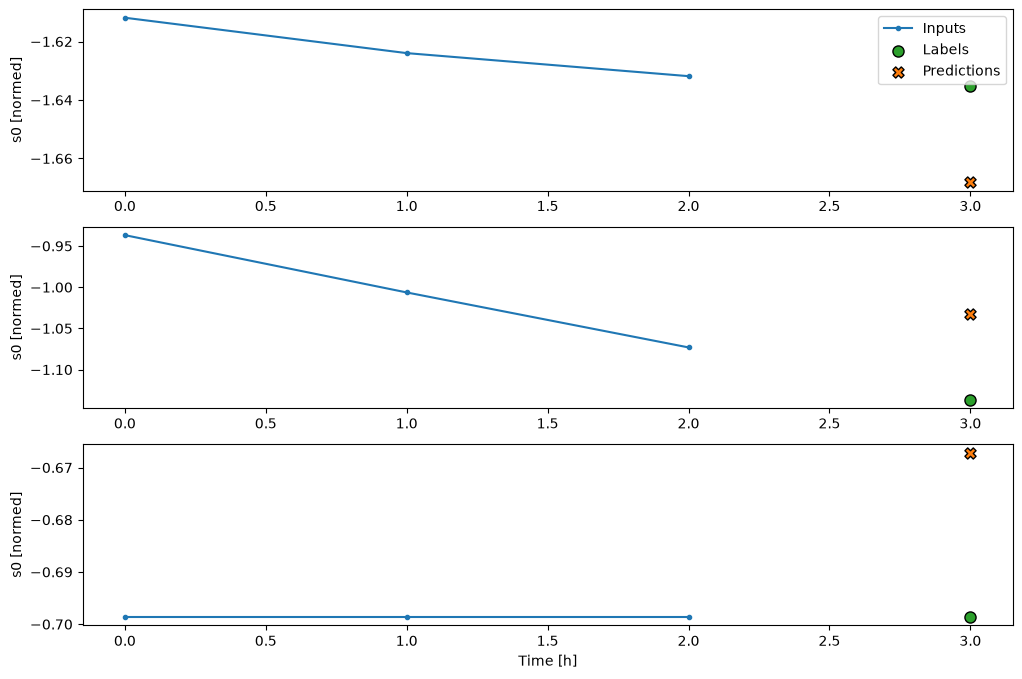

In [101]:
conv_window.plot(multi_step_dense)


Can only use this model on input windows of the exact same shape

In [103]:
print('Input shape:', wide_window.example[0].shape)
try:
  print('Output shape:', multi_step_dense(wide_window.example[0]).shape)
except Exception as e:
  print(f'\n{type(e).__name__}:{e}')


Input shape: (32, 24, 5)

ValueError:Exception encountered when calling Sequential.call().

Input 0 with name 'None' of layer 'dense_4' is incompatible with the layer: expected axis -1 of input shape to have value 15, but received input with shape (32, 120)

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 24, 5), dtype=float32)
  • training=None
  • mask=None
  • kwargs=<class 'inspect._empty'>


<h2>Convolution Neural Network</h3>
A convolution layer (tf.keras.layers.Conv1D) also takes multiple time steps as input to each prediction.

Below is the same model as multi_step_dense, re-written with a convolution.

Note the changes:

    The tf.keras.layers.Flatten and the first tf.keras.layers.Dense are replaced by a tf.keras.layers.Conv1D.
    The tf.keras.layers.Reshape is no longer necessary since the convolution keeps the time axis in its output.


In [104]:
conv_model = tf.keras.Sequential([
    tf.keras.layers.Conv1D(filters=32,
                           kernel_size=(CONV_WIDTH,),
                           activation='relu'),
    tf.keras.layers.Dense(units=32, activation='relu'),
    tf.keras.layers.Dense(units=1),
])
print("Conv model on `conv_window`")
print('Input shape:', conv_window.example[0].shape)
print('Output shape:', conv_model(conv_window.example[0]).shape)


Conv model on `conv_window`
Input shape: (32, 3, 5)
Output shape: (32, 1, 1)


In [105]:
history = compile_and_fit(conv_model, conv_window)

IPython.display.clear_output()
val_performance['Conv'] = conv_model.evaluate(conv_window.val, return_dict=True)
performance['Conv'] = conv_model.evaluate(conv_window.test, verbose=0, return_dict=True)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 0.0030 - mean_absolute_error: 0.0288


can be appled to any input window length

In [106]:
print("Wide window")
print('Input shape:', wide_window.example[0].shape)
print('Labels shape:', wide_window.example[1].shape)
print('Output shape:', conv_model(wide_window.example[0]).shape)


Wide window
Input shape: (32, 24, 5)
Labels shape: (32, 24, 1)
Output shape: (32, 22, 1)


Note that the output is shorter than the input. To make training or plotting work, you need the labels, and prediction to have the same length. So build a WindowGenerator to produce wide windows with a few extra input time steps so the label and prediction lengths match:

In [108]:
LABEL_WIDTH = 24
INPUT_WIDTH = LABEL_WIDTH + (CONV_WIDTH - 1)
wide_conv_window = WindowGenerator(
    input_width=INPUT_WIDTH,
    label_width=LABEL_WIDTH,
    shift=1,
    label_columns=['s0'])

wide_conv_window


Total window size: 27
Input indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]
Label indices: [ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26]
Label column name(s): ['s0']

In [109]:
print("Wide conv window")
print('Input shape:', wide_conv_window.example[0].shape)
print('Labels shape:', wide_conv_window.example[1].shape)
print('Output shape:', conv_model(wide_conv_window.example[0]).shape)


Wide conv window
Input shape: (32, 26, 5)
Labels shape: (32, 24, 1)
Output shape: (32, 24, 1)


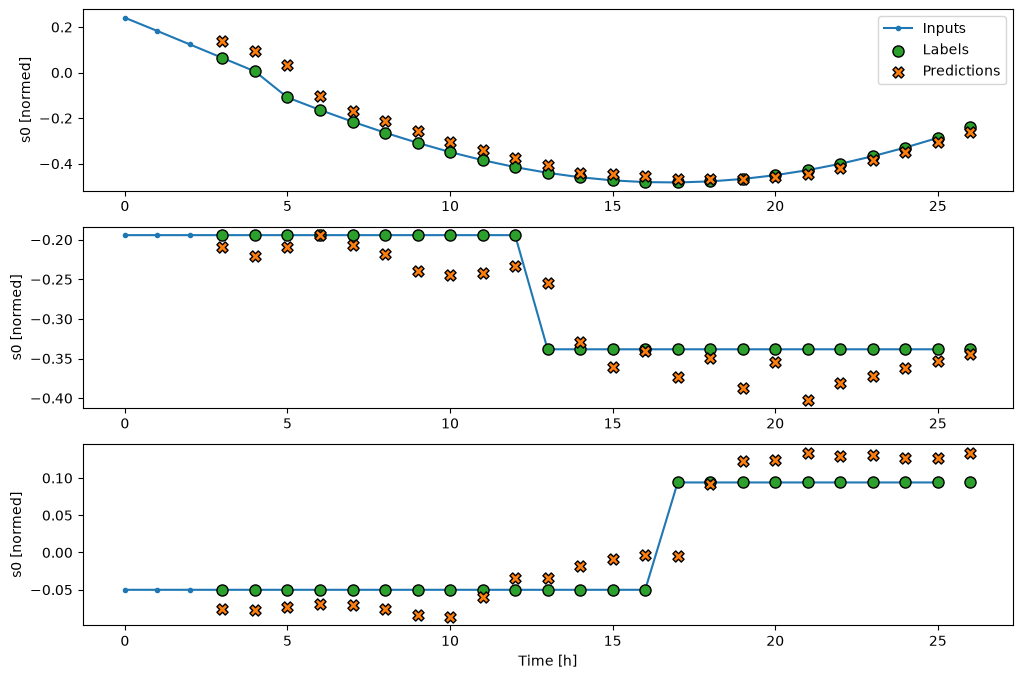

In [110]:
wide_conv_window.plot(conv_model)


<h1> Recurrent Neural Network - LSTM</h1>
An important constructor argument for all Keras RNN layers, such as tf.keras.layers.LSTM, is the return_sequences argument. This setting can configure the layer in one of two ways:

    If False, the default, the layer only returns the output of the final time step, giving the model time to warm up its internal state before making a single prediction:

An LSTM warming up and making a single prediction

    If True, the layer returns an output for each input. This is useful for:
        Stacking RNN layers.
        Training a model on multiple time steps simultaneously.


In [113]:
lstm_model = tf.keras.models.Sequential([
    # Shape [batch, time, features] => [batch, time, lstm_units]
    tf.keras.layers.LSTM(32, return_sequences=True),
    # Shape => [batch, time, features]
    tf.keras.layers.Dense(units=1)
])
print('Input shape:', wide_window.example[0].shape)
print('Output shape:', lstm_model(wide_window.example[0]).shape)

Input shape: (32, 24, 5)
Output shape: (32, 24, 1)


Note: This will give a pessimistic view of the model's performance. On the first time step, the model has no access to previous steps and, therefore, can't do any better than the simple linear and dense models shown earlier.

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0031 - mean_absolute_error: 0.0258


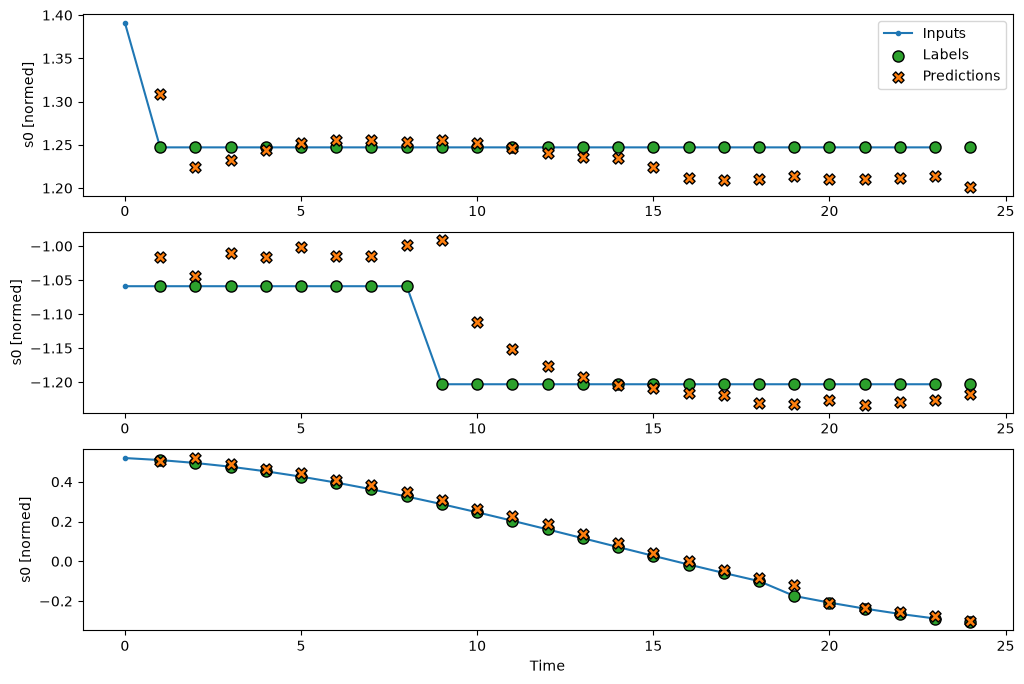

In [114]:
history = compile_and_fit(lstm_model, wide_window)

IPython.display.clear_output()
val_performance['LSTM'] = lstm_model.evaluate(wide_window.val, return_dict=True)
performance['LSTM'] = lstm_model.evaluate(wide_window.test, verbose=0, return_dict=True)
wide_window.plot(lstm_model)


In [115]:
cm = lstm_model.metrics[1]
cm.metrics


[<MeanAbsoluteError name=mean_absolute_error>]

In [116]:
val_performance


{'Baseline': {'loss': 0.0025009980890899897,
  'mean_absolute_error': 0.008081991225481033},
 'Linear': {'loss': 0.004838951397687197,
  'mean_absolute_error': 0.04639911279082298},
 'Dense': {'loss': 0.0027150975074619055,
  'mean_absolute_error': 0.020444033667445183},
 'Multi step dense': {'loss': 0.0023756236769258976,
  'mean_absolute_error': 0.02527019940316677},
 'Conv': {'loss': 0.0029838557820767164,
  'mean_absolute_error': 0.028803078457713127},
 'LSTM': {'loss': 0.0031118423212319613,
  'mean_absolute_error': 0.025755733251571655}}

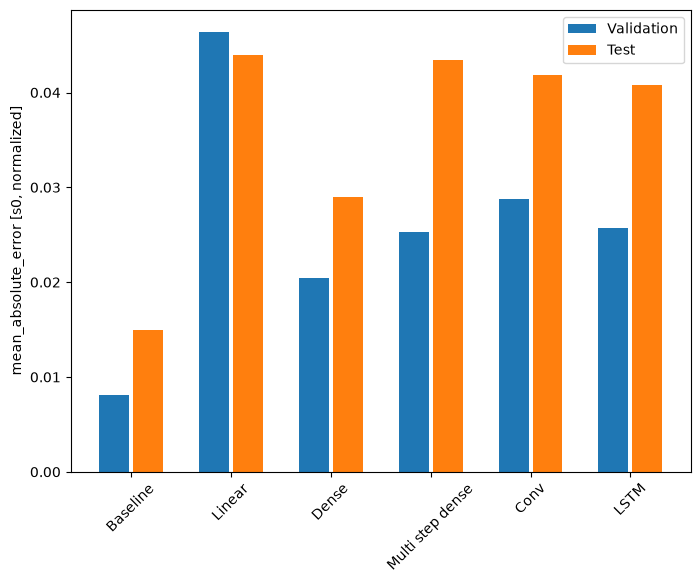

In [118]:
x = np.arange(len(performance))
width = 0.3
metric_name = 'mean_absolute_error'
val_mae = [v[metric_name] for v in val_performance.values()]
test_mae = [v[metric_name] for v in performance.values()]

plt.ylabel('mean_absolute_error [s0, normalized]')
plt.bar(x - 0.17, val_mae, width, label='Validation')
plt.bar(x + 0.17, test_mae, width, label='Test')
plt.xticks(ticks=x, labels=performance.keys(),
           rotation=45)
_ = plt.legend()


In [119]:
for name, value in performance.items():
  print(f'{name:12s}: {value[metric_name]:0.4f}')


Baseline    : 0.0149
Linear      : 0.0439
Dense       : 0.0290
Multi step dense: 0.0434
Conv        : 0.0419
LSTM        : 0.0408


The baseline model actually performed best for s0 - this is probably due to the snake scans - s0 stays constant for each row. It would work less well for s1 or s2

<h1> Multi Output models

In [ ]:
single_step_window = WindowGenerator(
    # `WindowGenerator` returns all features as labels if you
    # don't set the `label_columns` argument.
    input_width=1, label_width=1, shift=1, label_columns=["s0", "s1"])

wide_window = WindowGenerator(
    input_width=24, label_width=24, shift=1,label_columns=["s0", "s1"])

for example_inputs, example_labels in wide_window.train.take(1):
  print(f'Inputs shape (batch, time, features): {example_inputs.shape}')
  print(f'Labels shape (batch, time, features): {example_labels.shape}')


Inputs shape (batch, time, features): (32, 24, 5)
Labels shape (batch, time, features): (32, 24, 2)


<h3>Baseline

In [159]:
baseline = Baseline(label_index=column_indices['s0'])
baseline.compile(loss=tf.keras.losses.MeanSquaredError(),
                 metrics=[tf.keras.metrics.MeanAbsoluteError()])
val_performance = {}
performance = {}
val_performance['Baseline'] = baseline.evaluate(wide_window.val, return_dict=True)
performance['Baseline'] = baseline.evaluate(wide_window.test, verbose=0, return_dict=True)
# wide_window.plot(baseline, max_subplots=6)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0770 - mean_absolute_error: 0.6025 


<h3>Dense

In [149]:
dense = tf.keras.Sequential([
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=num_features)
])
history = compile_and_fit(dense, single_step_window)

IPython.display.clear_output()
val_performance['Dense'] = dense.evaluate(single_step_window.val, return_dict=True)
performance['Dense'] = dense.evaluate(single_step_window.test, verbose=0, return_dict=True)


Epoch 1/20


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


ValueError: Dimensions must be equal, but are 2 and 5 for '{{node compile_loss/mean_squared_error/sub}} = Sub[T=DT_FLOAT](data_1, sequential_9_1/dense_18_1/BiasAdd)' with input shapes: [?,1,2], [?,1,5].

<h3>LSTM

In [127]:
%%time
wide_window = WindowGenerator(
    input_width=24, label_width=24, shift=1)

lstm_model = tf.keras.models.Sequential([
    # Shape [batch, time, features] => [batch, time, lstm_units]
    tf.keras.layers.LSTM(32, return_sequences=True),
    # Shape => [batch, time, features]
    tf.keras.layers.Dense(units=num_features)
])

history = compile_and_fit(lstm_model, wide_window)

IPython.display.clear_output()
val_performance['LSTM'] = lstm_model.evaluate( wide_window.val, return_dict=True)
performance['LSTM'] = lstm_model.evaluate( wide_window.test, verbose=0, return_dict=True)

print()


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0087 - mean_absolute_error: 0.0372

CPU times: user 39.1 s, sys: 3.57 s, total: 42.6 s
Wall time: 16.5 s


<h3> Advanced: Residual Connections</h3>
The Baseline model from earlier took advantage of the fact that the sequence doesn't change drastically from time step to time step. Every model trained in this tutorial so far was randomly initialized, and then had to learn that the output is a a small change from the previous time step.

While you can get around this issue with careful initialization, it's simpler to build this into the model structure.

It's common in time series analysis to build models that instead of predicting the next value, predict how the value will change in the next time step. Similarly, residual networks—or ResNets—in deep learning refer to architectures where each layer adds to the model's accumulating result.

That is how you take advantage of the knowledge that the change should be small.

Essentially, this initializes the model to match the Baseline. For this task it helps models converge faster, with slightly better performance.

This approach can be used in conjunction with any model discussed in this tutorial.

Here, it is being applied to the LSTM model, note the use of the tf.initializers.zeros to ensure that the initial predicted changes are small, and don't overpower the residual connection. There are no symmetry-breaking concerns for the gradients here, since the zeros are only used on the last layer.

In [131]:
class ResidualWrapper(tf.keras.Model):
  def __init__(self, model):
    super().__init__()
    self.model = model

  def call(self, inputs, *args, **kwargs):
    delta = self.model(inputs, *args, **kwargs)

    # The prediction for each time step is the input
    # from the previous time step plus the delta
    # calculated by the model.
    return inputs + delta


In [132]:
%%time
residual_lstm = ResidualWrapper(
    tf.keras.Sequential([
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.Dense(
        num_features,
        # The predicted deltas should start small.
        # Therefore, initialize the output layer with zeros.
        kernel_initializer=tf.initializers.zeros())
]))

history = compile_and_fit(residual_lstm, wide_window)

IPython.display.clear_output()
val_performance['Residual LSTM'] = residual_lstm.evaluate(wide_window.val, return_dict=True)
performance['Residual LSTM'] = residual_lstm.evaluate(wide_window.test, verbose=0, return_dict=True)
print()

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0083 - mean_absolute_error: 0.0335

CPU times: user 37.2 s, sys: 3.83 s, total: 41 s
Wall time: 16.2 s


<h3> Performance

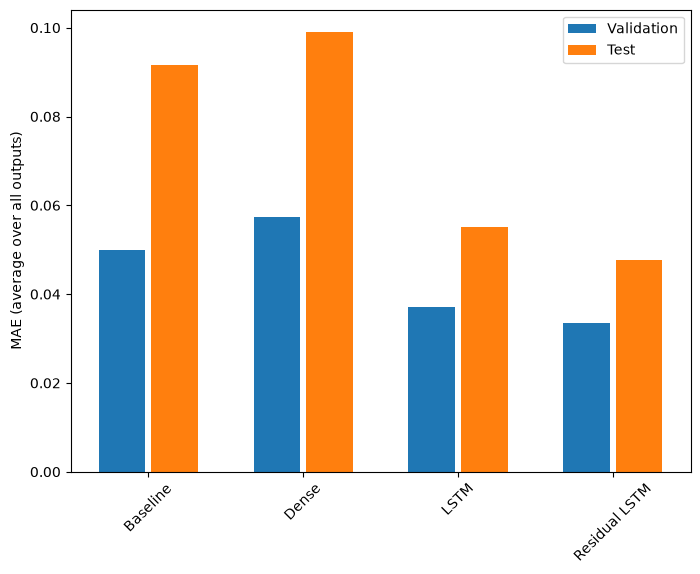

In [133]:
x = np.arange(len(performance))
width = 0.3

metric_name = 'mean_absolute_error'
val_mae = [v[metric_name] for v in val_performance.values()]
test_mae = [v[metric_name] for v in performance.values()]

plt.bar(x - 0.17, val_mae, width, label='Validation')
plt.bar(x + 0.17, test_mae, width, label='Test')
plt.xticks(ticks=x, labels=performance.keys(),
           rotation=45)
plt.ylabel('MAE (average over all outputs)')
_ = plt.legend()


In [134]:
for name, value in performance.items():
  print(f'{name:15s}: {value[metric_name]:0.4f}')


Baseline       : 0.0917
Dense          : 0.0991
LSTM           : 0.0551
Residual LSTM  : 0.0477
